In [1]:
import pandas as pd

In [2]:
import kagglehub 
from kagglehub import KaggleDatasetAdapter

In [4]:
# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

Path to dataset files: C:\Users\ASUS\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3


In [5]:
import os
file_path = os.path.join(path, "amz_uk_price_prediction_dataset.csv")
df = pd.read_csv(file_path)

In [8]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Lab - EDA Univariate Analysis: Diving into Amazon UK Product Insights

**Objective**: Explore the product listing dynamics on Amazon UK to extract actionable business insights. By understanding the distribution, central tendencies, and relationships of various product attributes, businesses can make more informed decisions on product positioning, pricing strategies, and inventory management.

**Dataset**: This lab utilizes the [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)
which provides information on product categories, brands, prices, ratings, and more from from Amazon UK. You'll need to download it to start working with it.

In [9]:
df.shape

(2443651, 9)

From here we conclude that there are initially 2443651 rows and 9 columns.

In [10]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2443651 entries, 0 to 2443650
Data columns (total 9 columns):
 #   Column             Dtype  
---  ------             -----  
 0   uid                int64  
 1   asin               object 
 2   title              object 
 3   stars              float64
 4   reviews            int64  
 5   price              float64
 6   isBestSeller       bool   
 7   boughtInLastMonth  int64  
 8   category           object 
dtypes: bool(1), float64(2), int64(3), object(3)
memory usage: 151.5+ MB


In [11]:
df.isnull().sum()

uid                  0
asin                 0
title                0
stars                0
reviews              0
price                0
isBestSeller         0
boughtInLastMonth    0
category             0
dtype: int64

No missing values, apparently, in any of the 9 columns.

In [12]:
df.duplicated().sum()

np.int64(0)

No duplicates rows detected, either.

### Part 1: Understanding Product Categories

**Business Question**: What are the most popular product categories on Amazon UK, and how do they compare in terms of listing frequency?

1. **Frequency Tables**:
    - Generate a frequency table for the product `category`.
    - Which are the top 5 most listed product categories?

2. **Visualizations**:
    - Display the distribution of products across different categories using a bar chart. *If you face problems understanding the chart, do it for a subset of top categories.*
    - For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings?

In [13]:
df.columns

Index(['uid', 'asin', 'title', 'stars', 'reviews', 'price', 'isBestSeller',
       'boughtInLastMonth', 'category'],
      dtype='object')

In [14]:
df["category"].value_counts()

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
                                           ...  
Alexa Built-In Devices                       107
Motorbike Chassis                            107
Plugs                                        107
Smart Home Security & Lighting               104
Smart Speakers                                54
Name: count, Length: 296, dtype: int64

This is the frequency table which shows how many times each category appears.

In [21]:
df["category"].value_counts().head(5)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64

2. These are the top 5 most listed product categories.

In [16]:
import matplotlib.pyplot as plt
import seaborn as sns

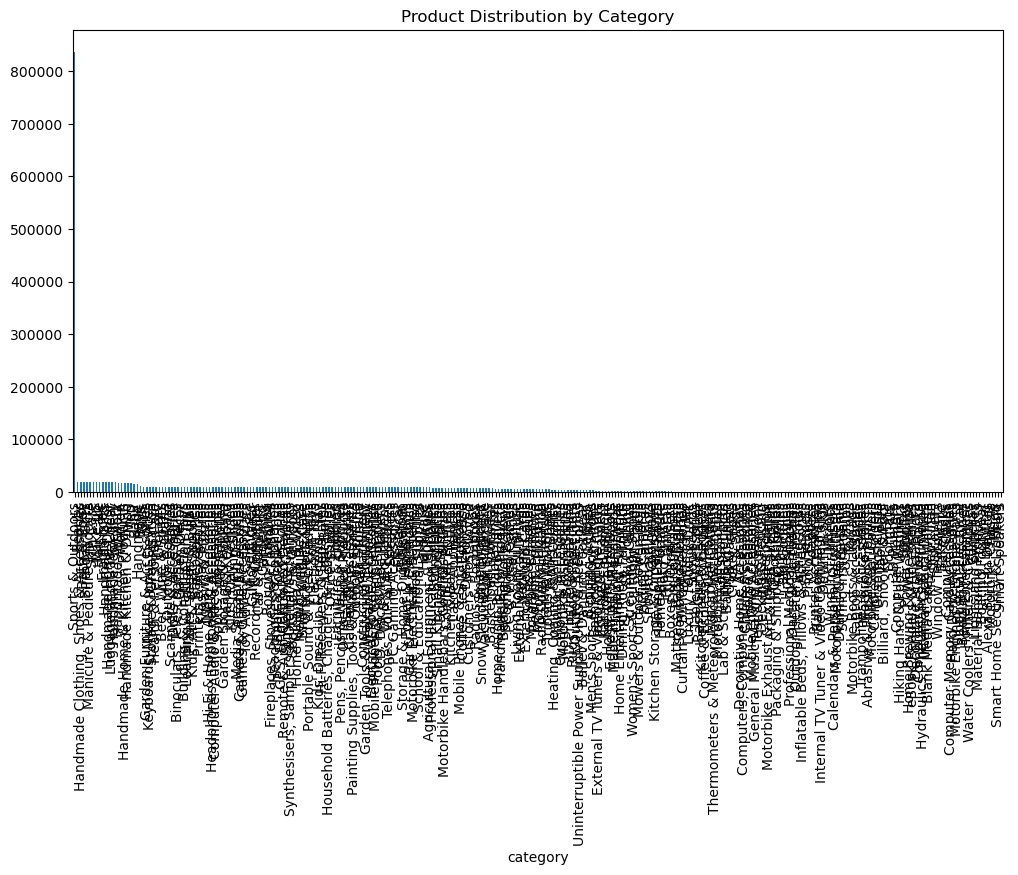

In [17]:
df["category"].value_counts().plot(kind="bar", figsize=(12,6))
plt.title("Product Distribution by Category")
plt.show()

This is totally unsiotable for visualisation and presentation purposes. The plot is simply too crowded at this stage.

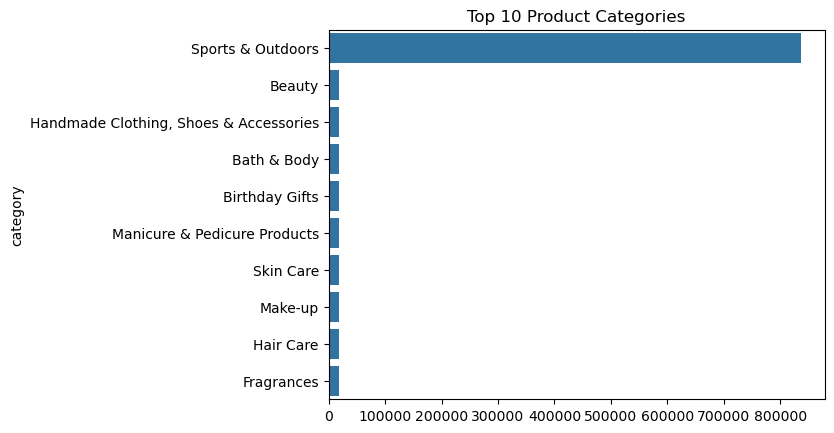

In [18]:
top10_categories = df["category"].value_counts().head(10)

sns.barplot(x=top10_categories.values, y=top10_categories.index)
plt.title("Top 10 Product Categories")
plt.show()

By setting the categories to a subset of 10 only, one can have a better view of the dominating ones. This also improves visualisation.

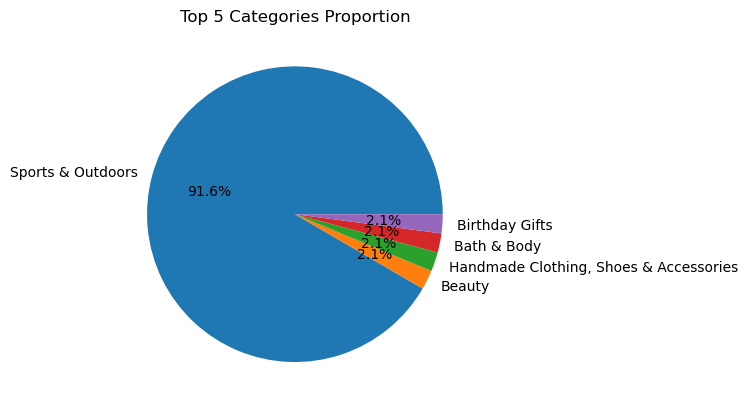

In [20]:
top5_categories = df["category"].value_counts().head(5)

top5_categories.plot(kind="pie", autopct="%1.1f%%")
plt.title("Top 5 Categories Proportion")
plt.ylabel("")
plt.show()

Setting categories to a subset of 5 only. One concludes that the Sports & Outdoors categories clearly dominates the listings, as previously observed.

### Part 2: Delving into Product Pricing

**Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `price` of products.
    - What's the average price point of products listed? How does this compare with the most common price point (mode)?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

In [53]:
display(df["price"].mean())
display(df["price"].median())
display(df["price"].mode())

np.float64(89.24453985892305)

19.09

0    9.99
Name: price, dtype: float64

1. **Measures of Centrality**:

The average product price (mean) is approximately 89.24 which far off the most common price point (mode) of 9.99.

The mean price is higher than the median price in this case, meaning that the price distribution is right-skewed. In other words there are expensive product outliers.

In [54]:
df.describe()   # for all numerical columns

,uid,stars,reviews,price,boughtInLastMonth
count,2.443631e+06,2.443631e+06,2.443631e+06,2.443631e+06,2.443631e+06
mean,1.370547e+06,2.152817e+00,4.805891e+02,8.924454e+01,2.589720e+01
std,8.160583e+05,2.194863e+00,5.944042e+03,3.456102e+02,2.404847e+02
min,1.000000e+00,0.000000e+00,0.000000e+00,1.000000e-02,0.000000e+00
25%,6.589205e+05,0.000000e+00,0.000000e+00,9.990000e+00,0.000000e+00
50%,1.349032e+06,0.000000e+00,0.000000e+00,1.909000e+01,0.000000e+00
75%,2.060690e+06,4.400000e+00,5.900000e+01,4.599000e+01,0.000000e+00
max,2.828593e+06,5.000000e+00,1.356658e+06,1.000000e+05,5.000000e+04


2. **Measures of Dispersion**:


In [55]:
df["price"].var()

# price variance

119446.39774346988

In [56]:
df["price"].std()

# price standard deviation

345.61018177054603

In [57]:
df["price"].max() - df["price"].min()

# price range

99999.99

In [58]:
df["price"].quantile(0.75) - df["price"].quantile(0.25)

np.float64(36.0)

In [59]:
display(df["price"].mean())
display(df["price"].std())

np.float64(89.24453985892305)

345.61018177054603

2. **Measures of Dispersion**:
    - Product prices seem to have a wide range among them (100000). 
    - Indicators of a significant spread in prices are present, given that the standard deviation is large relative to the mean.

- If std is large relative to mean: high spread
- If std is small relative to mean: low spread

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing.

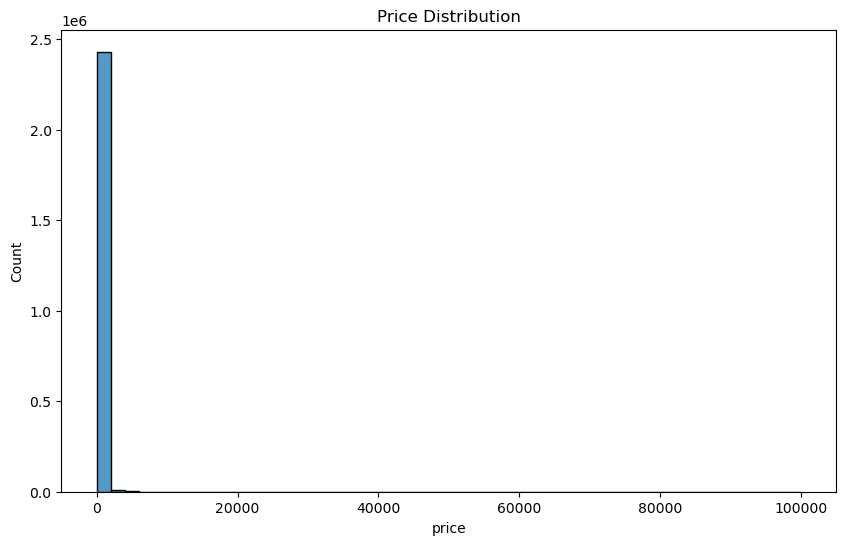

In [60]:
plt.figure(figsize=(10,6))
sns.histplot(df["price"], bins=50)    # using a histplot to show price ranges
plt.title("Price Distribution")
plt.show()

The problem here is that the distribution is skewed (right-skewed), meaning that the lower price ranges compress everything else. So, let's try and limit the x-axis to begin with.

From here, one can also tell there are products that are priced significantly higher than the rest (highest are in order of hunderds of thousands - 10 to the 5).

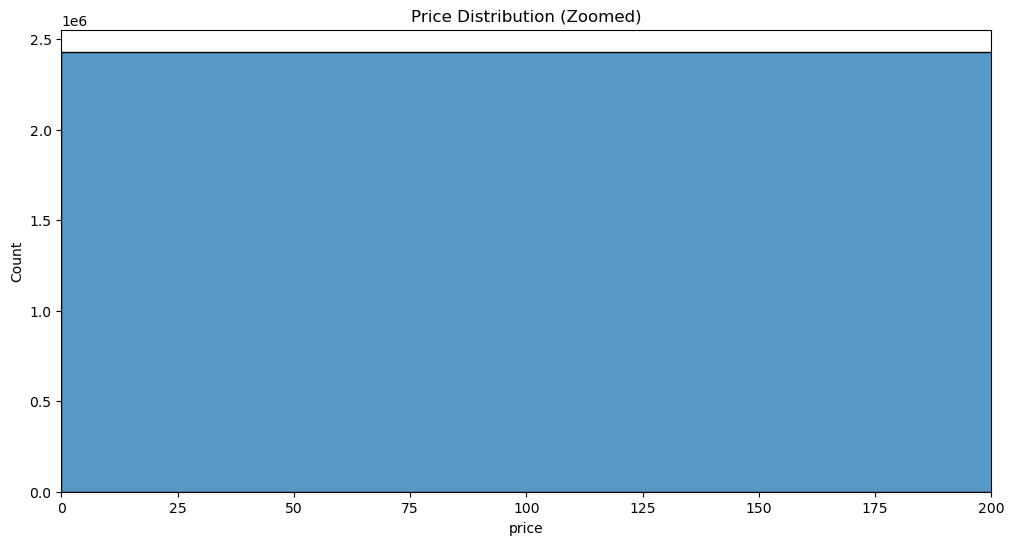

In [61]:
plt.figure(figsize=(12,6))
sns.histplot(df["price"], bins=50)
plt.xlim(0, 200)  # adjust based on your data
plt.title("Price Distribution (Zoomed)")
plt.show()

Not ideal. x-axis limit is clearly not enough, which suggest we need a better scale technique still.

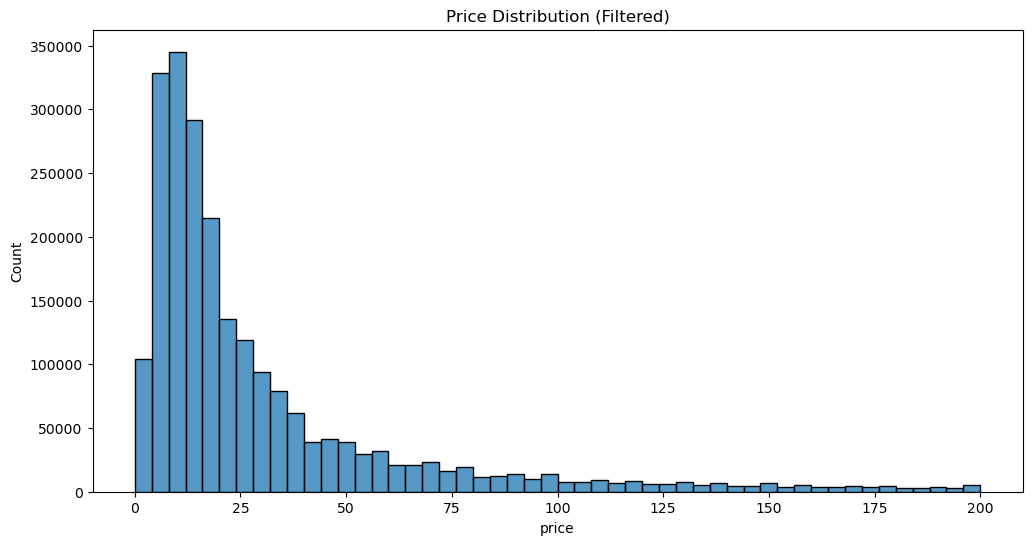

In [62]:
filtered_outliers = df[df["price"] < 200]

plt.figure(figsize=(12,6))
sns.histplot(filtered_outliers["price"], bins=50)
plt.title("Price Distribution (Filtered)")
plt.show()

Another strategy could be filtering out outliers (temporarily), by limiting the prices to, say 200, in order to get a better view of the left hand side of the distribution, where it is more compressed.

From here, one can also tell there are products that are priced significantly higher than the rest (highest are in order of hunderds of thousands - 10 to the 5).

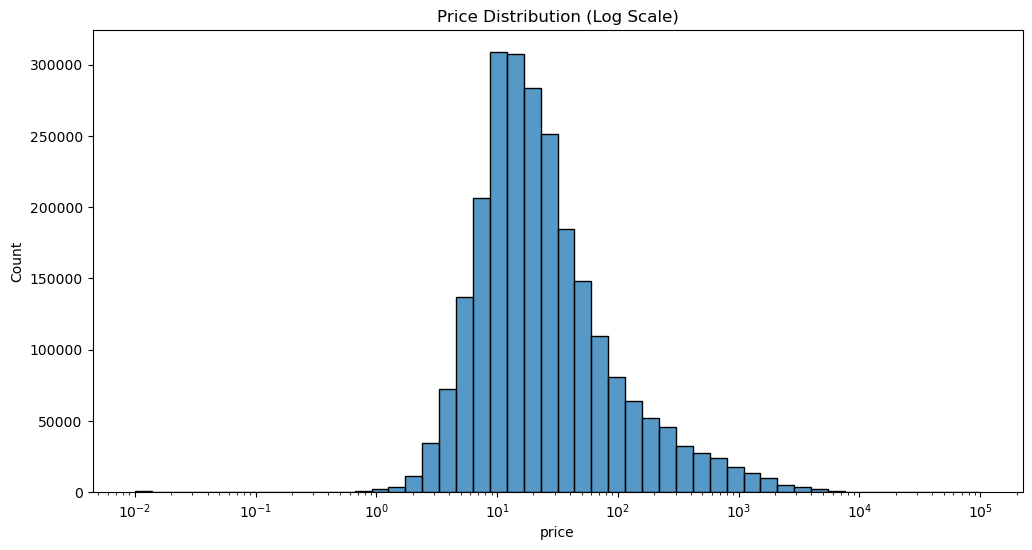

In [63]:
df_filtered = df[df["price"] > 0]

plt.figure(figsize=(12,6))
sns.histplot(df_filtered["price"], bins=50, log_scale=True)
plt.title("Price Distribution (Log Scale)")
plt.show()

Yet another good option is to with a logarithmic scale which uses orders of mangnitude in order to spread values for better visualisation while helping with the data structure visualisation. This is due to the high number of cheap products (left hand side of the distribution).

NOTE: to ensure that we remove any zeros (given the nature of the logarithmic function), we do df_filtered = df[df["price"] > 0] prior to plotting.

From here, one can also tell there are products that are priced significantly higher than the rest (highest are in order of hunderds of thousands - 10 to the 5).

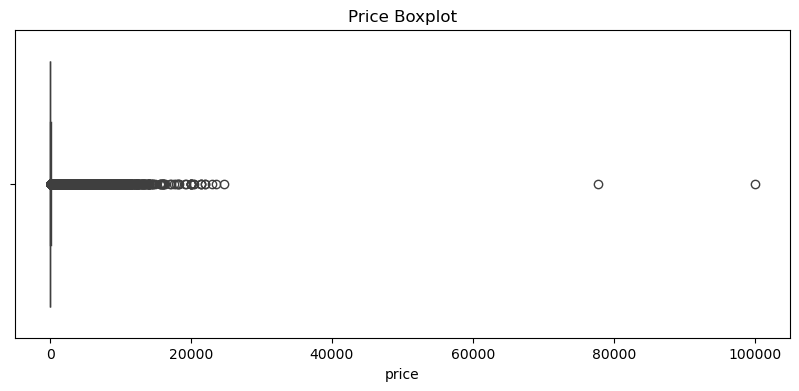

In [64]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df["price"])
plt.title("Price Boxplot")
plt.show()

As expected, the box plot shows not only the spread of prices, but also the outliers (10000, as previously seen).

However, due to data being extremely skewed: 

- Box gets squeezed to one side
- Median line becomes hard to see
- Outliers may look like they’re “inside” because scale is stretched

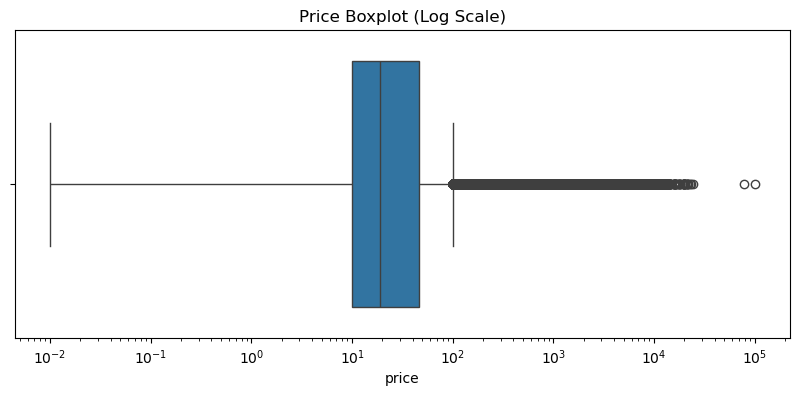

In [65]:
plt.figure(figsize=(10,4))
sns.boxplot(x=df_filtered["price"])
plt.xscale("log")
plt.title("Price Boxplot (Log Scale)")
plt.show()

So, again, we use a log scale to help us better visualise the box plot.

<Axes: xlabel='price'>

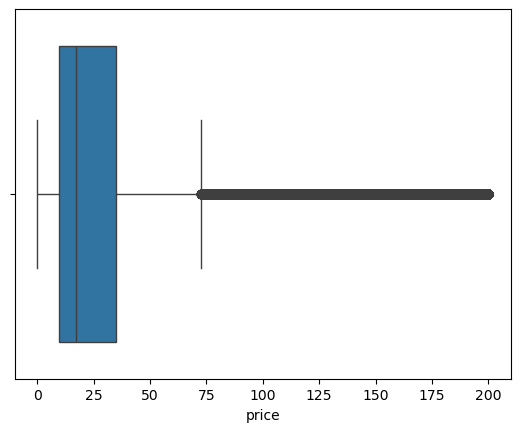

In [66]:
sns.boxplot(x=df_filtered[df_filtered["price"] < 200]["price"])

Or by limiting the x-axis yet again.

In this context, the boxplot tells us:

1. Spread (normal price range)
The box (IQR) = where most products are priced
- This is the “Typical price range”

2. Median (typical price point)
This is the line inside the box
- “Middle price of products”

3. Outliers (expensive products)
Points outside the whiskers
- These are significantly higher-priced products
- Rare compared to the rest

So, are there products priced significantly higher?

The points far to the right of the box (long right whisker) suggest so

So yes:
There are high-price outliers, indicating a small number of products priced significantly above the majority.

In terms of spread:
A small box suggests that prices are similar.

Otherwise, a wide box would indicate that prices vary a lot (high variability).

Because this data is skewed:

- Without a log scale:

    Outliers may not be visible clearly
    Box looks compressed

- With a log scale:

    One clearly sees:
    Main price cluster
    Expensive outliers


In a nutshell:
Box: normal prices
Outside points: unusual/expensive

Distance: how extreme they are

The boxplot shows that most products fall within a relatively narrow price range, while several high-price outliers indicate the presence of significantly more expensive products.

### Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

---

**Submission**: Submit a Jupyter Notebook which contains code and a business-centric report summarizing your findings.

In [68]:
df_rated_prod = df[df["stars"] > 0]

Here's we are ensuring that we work with a subset of the entire product dataframe that does have associated product ratings. In other words > 0.

In [69]:
df_rated_prod["stars"].mean()

np.float64(4.319157135937076)

The average product rating is approximately 4.32 stars.

In [70]:
df_rated_prod["stars"].median()

4.4

The middle rating is 4.4. stars.

In [71]:
df_rated_prod["stars"].mode()

0    4.5
Name: stars, dtype: float64

The most common rating is 4.5 stars.

So, apparently, Amazon UK customers frequently (mode) rate products well, with a common trend at 4.5 stars.

The overall satisfaction level (mean) of Amazon UK customers (at 4.32) is also pretty good.

On the other hand, Amazon UK customers typically (median) give a rating (robust to extremes) of 4.4.

Typically:

- If mean ≈ median ≈ mode:
        Ratings are consistent
- If mean < median:
        Some low ratings pulling average down
- If mode is high:
        Most users give high ratings


In this case, ratings are therefore consistent, given that mean ≈ median ≈ mode.

In [72]:
df_rated_prod["stars"].var()

0.30834541421954725

In [73]:
df_rated_prod["stars"].std()

0.5552885864301078

In [ ]:
df_rated_prod["stars"].quantile(0.75) - df_rated_prod["stars"].quantile(0.25)

# this is the spread of the middle 50%

np.float64(0.5)

A standard deviation of 0.56 suggests moderate variability, indicating that customer ratings are rather consistent.

IQR is between 0 to 1, which means that most ratings are similar.

In this case, we have low std/low IQR.

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [78]:
df_rated_prod["stars"].skew()

np.float64(-2.379562204075365)

- So:

≈ skew 0 indicates a symmetric distribution (roughly normal)
> 0 (positive skew) indicates tail to the right (most ratings would be low and a few high)
< 0 (negative skew) indicates tail to the left (most ratings would be high and a few low)

In this case, there is a negative skew, meaning that the tail is to the left (most ratings are high and a few low).

The distribution is negatively skewed, indicating that ratings tend to be higher overall.

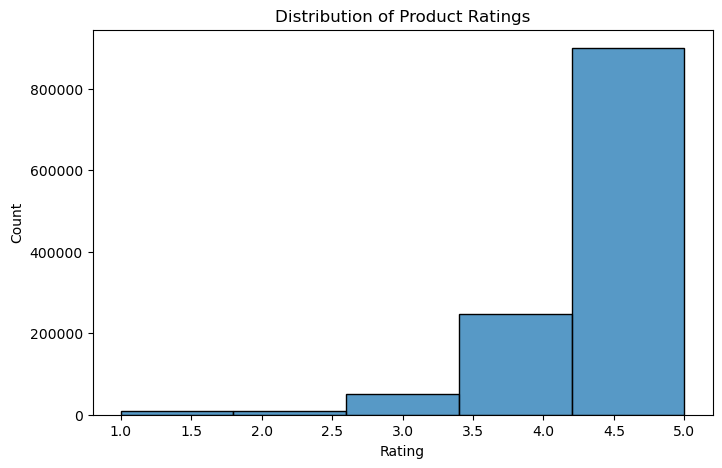

In [80]:
plt.figure(figsize=(8,5))
sns.histplot(df_rated_prod["stars"], bins=5)
plt.title("Distribution of Product Ratings")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.show()

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

Clearly, the most common ratings are above 4, which indicates high satisfaction overall.